# Setup

In [69]:
import os
import numpy as np
import matplotlib.pyplot as plt
from skimage.color import rgb2gray
from skimage.filters import sobel
from scipy.interpolate import splprep, splev
from PIL import Image
import cv2
from typing import List, Union, Optional, Tuple

In [27]:
# Dirs and params
CelebAMask_HQ_dir = '/Users/adipani3/datasets/CelebAMask-HQ/CelebAMask-HQ'

# Data

In [146]:
celebamaskhq_face_indices = [281, 514, 643, 685, 1229]  # These are the indices of the images in CelebA-HQ that we will use for faces
# image_indices = [112, 116, 154, 1115, 1124, 1170, 1350, 2001, 2020, 2564]
face_annotation_types = {
    'r_ear': 15, 'r_eye': 10, 'skin': 90, 'nose': 25,
    'mouth': 20, 'l_eye': 10, 'l_ear': 15,
}
faces_annotation_num_points = list(face_annotation_types.values())
faces = {}
for idx, imgidx in enumerate(celebamaskhq_face_indices):
    annotation_types = list(face_annotation_types.keys())
    ann_folder_idx = imgidx // 2000
    mask_paths = [
        f'{CelebAMask_HQ_dir}/CelebAMask-HQ-mask-anno/{ann_folder_idx}/{imgidx:05d}_{annotype}.png'
        for annotype in annotation_types
    ]
    faces[idx+1] = {
        'image_idx': imgidx,
        'image_path': f'{CelebAMask_HQ_dir}/CelebA-HQ-img/{imgidx}.jpg',
        'mask_paths': mask_paths
    }
annotation_types = {
        'r_eye': 20, 'skin': 90, 'nose': 40,
        'mouth': 35, 'l_eye': 20,
    }

bodies = {}
scenes = {}
objects = {}

In [104]:
def get_contour(
    masks: List[Union[str, Image.Image, np.ndarray]],
    num_points: Union[int, List[int]] = 200,
    smoothing_factor: float = 5.0,
    target_shape: Optional[tuple] = None,
) -> Tuple[List[np.ndarray], List[np.ndarray]]:
    """
    Extracts smooth B-spline contours from segmentation masks and returns
    both sampled contour points and their normal angles (tangent + 90 degrees).

    Args:
        masks (list): Each element can be:
            - str: path to a segmentation mask file
            - PIL.Image.Image: PIL image object
            - np.ndarray: grayscale or RGB numpy array
        num_points (int or list): Number of sampled points per contour,
                                  or list specifying per-mask counts.
        smoothing_factor (float): Spline smoothing factor (higher = smoother).
        target_shape (tuple, optional): (height, width) to rescale contours.

    Returns:
        Tuple:
            - points_list: list of (N, 2) arrays of sampled (x, y) coordinates
            - angles_list: list of (N,) arrays of angles (in degrees) of the
                           normal direction ((tangent + 90) % 360)
    """
    # --- Normalize num_points ---
    if isinstance(num_points, int):
        num_points = [num_points] * len(masks)
    elif len(num_points) != len(masks):
        raise ValueError("num_points list must match number of masks")

    points_list, angles_list = [], []

    for mask, n_points in zip(masks, num_points):
        # --- Load the mask ---
        if isinstance(mask, str):
            mask_img = cv2.imread(mask, cv2.IMREAD_GRAYSCALE)
            if mask_img is None:
                print(f"[Warning] Could not load: {mask}")
                points_list.append(np.array([]))
                angles_list.append(np.array([]))
                continue
        elif isinstance(mask, Image.Image):
            mask_img = np.array(mask.convert("L"))
        elif isinstance(mask, np.ndarray):
            if mask.ndim == 3:
                mask_img = cv2.cvtColor(mask, cv2.COLOR_BGR2GRAY)
            else:
                mask_img = mask.astype(np.uint8)
        else:
            raise TypeError(f"Unsupported input type: {type(mask)}")

        # --- Threshold + find contour ---
        _, mask_bin = cv2.threshold(mask_img, 127, 255, cv2.THRESH_BINARY)
        contours, _ = cv2.findContours(mask_bin, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        if not contours:
            points_list.append(np.array([]))
            angles_list.append(np.array([]))
            continue

        main_contour = max(contours, key=cv2.contourArea).squeeze()
        if main_contour.ndim != 2 or len(main_contour) < 4:
            points_list.append(np.array([]))
            angles_list.append(np.array([]))
            continue

        # --- Optional rescaling ---
        if target_shape:
            h, w = mask_bin.shape[:2]
            scale_x, scale_y = target_shape[1] / w, target_shape[0] / h
            main_contour = (main_contour * np.array([scale_x, scale_y])).astype(np.float32)

        # --- Fit closed B-spline ---
        try:
            x, y = main_contour[:, 0], main_contour[:, 1]
            tck, u = splprep([x, y], s=smoothing_factor, per=True, k=3)
            u_new = np.linspace(0, 1, n_points)

            # Get sampled points and derivatives
            x_new, y_new = splev(u_new, tck, der=0)
            dx, dy = splev(u_new, tck, der=1)

            # Tangent and normal angles
            tangents = np.degrees(np.arctan2(dy, dx)) % 360
            normals = (tangents + 90) % 360

            smooth_points = np.stack((x_new, y_new), axis=-1).astype(np.float32)

            points_list.append(smooth_points)
            angles_list.append(normals.astype(np.float32))

        except Exception as e:
            print(f"[Warning] Spline fitting failed: {e}")
            points_list.append(np.array([]))
            angles_list.append(np.array([]))

    return points_list, angles_list


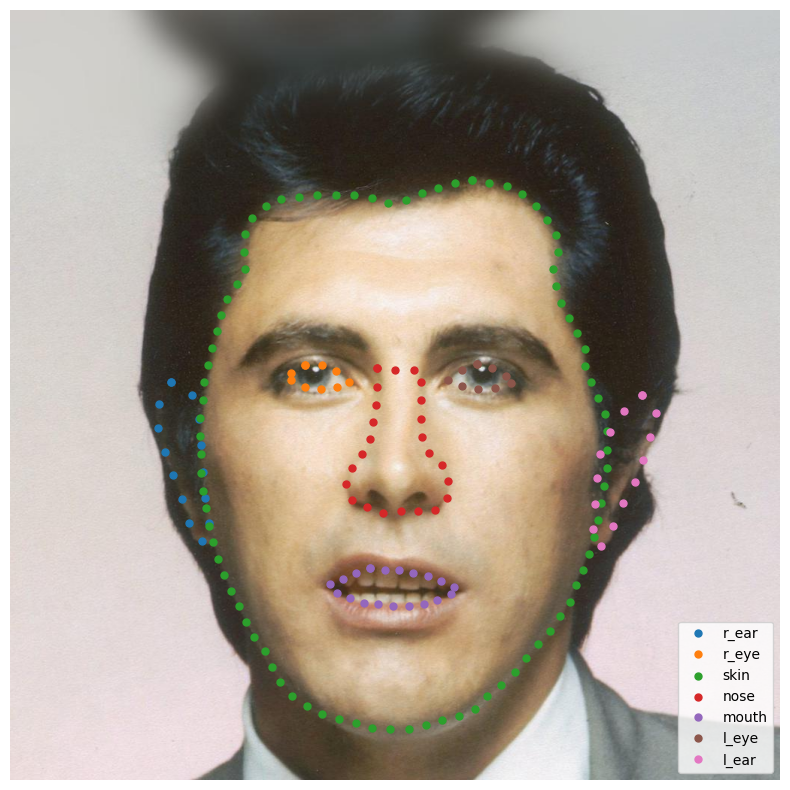

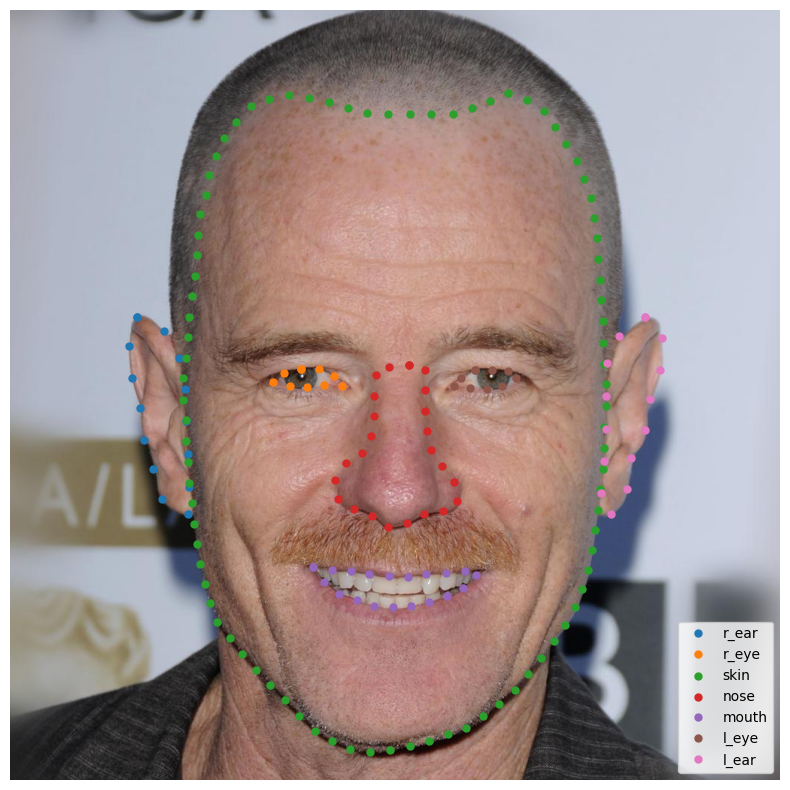

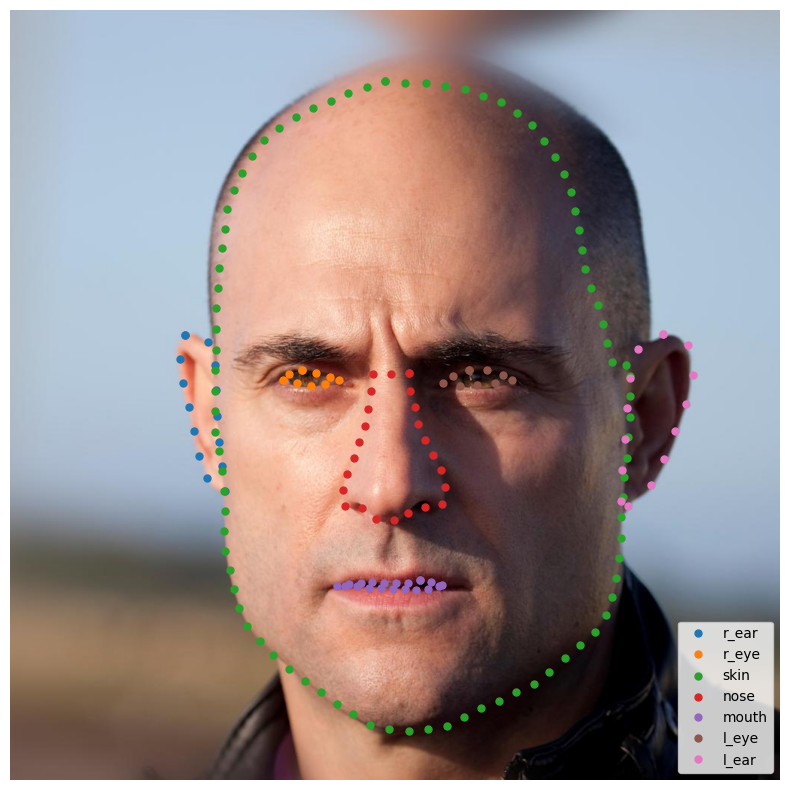

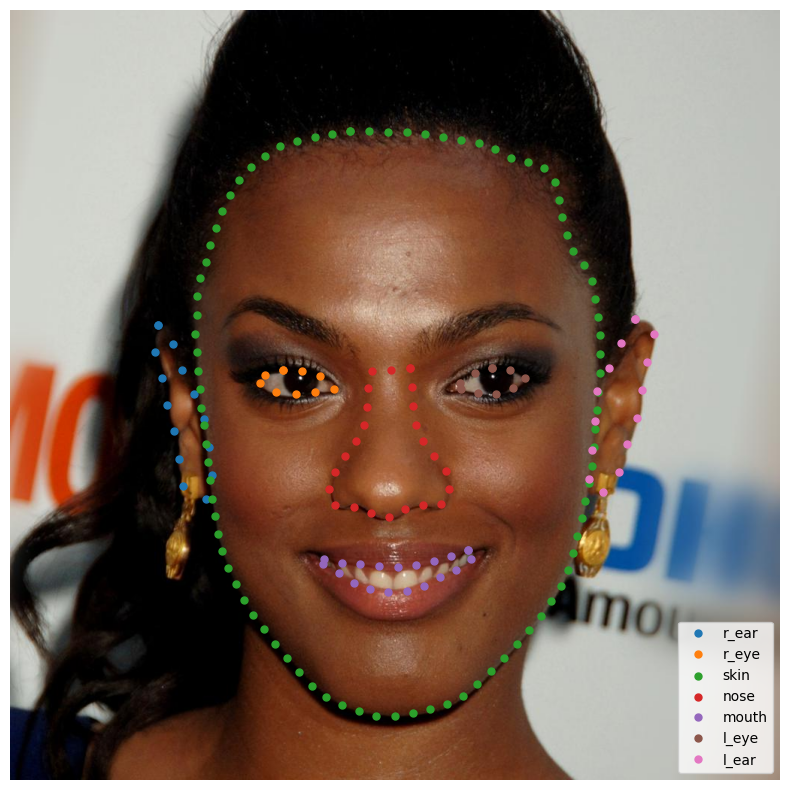

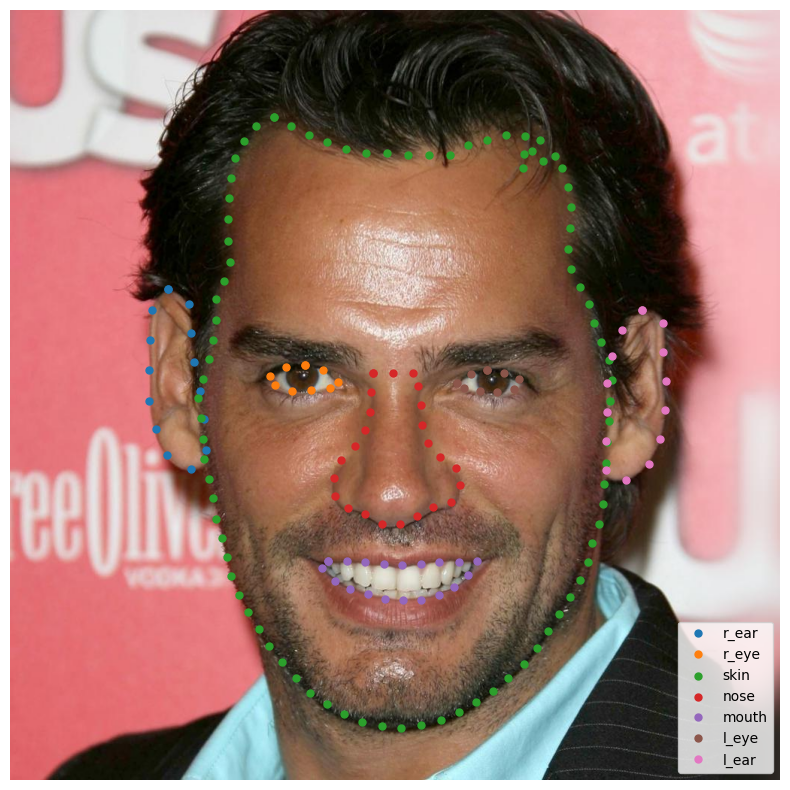

In [147]:
# Load first face image, compute smooth contours from its masks, and overlay them
for face in faces.values():
    img_bgr = cv2.imread(face['image_path'])
    if img_bgr is None:
        raise FileNotFoundError(f"Image not found: {face['image_path']}")
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    h, w = img_rgb.shape[:2]

    contours_points, _ = get_contour(
        face['mask_paths'],
        num_points=faces_annotation_num_points,
        smoothing_factor=5.0,
        target_shape=(h, w),
    )

    plt.figure(figsize=(8, 8))
    plt.imshow(img_rgb)
    colors = plt.cm.tab10.colors

    for i, pts in enumerate(contours_points):
        if pts.size == 0:
            continue
        color = colors[i % len(colors)]
        label = list(face_annotation_types.keys())[i]
        plt.plot(pts[:, 0], pts[:, 1], '.', color=color, markersize=10, label=label)

    plt.axis('off')
    plt.legend(loc='lower right')
    plt.tight_layout()
    plt.show()

In [148]:
def generate_gabor_stimuli(
    points_list: list[np.ndarray],
    angles_list: list[np.ndarray],
    image_size: tuple[int, int],
    gabor_size: int = 21,
    spatial_freq: float = 0.15,
    phase: float = 0.0,
    contrast: float = 1.0,
    sigma: float | None = None,
    add_random: bool = False,
    num_random: int = 100,
    random_angle: bool = True,
    return_image: bool = True,
    show: bool = True
) -> np.ndarray | None:
    """
    Generate an image with Gabor patches placed at contour points and (optionally) random positions.
    The background is fixed at gray = (127,127,127).

    Args:
        points_list (list[np.ndarray]): List of (N, 2) arrays of contour points.
        angles_list (list[np.ndarray]): List of (N,) arrays of normal angles (degrees).
        image_size (tuple[int, int]): (height, width) of output image in pixels.
        gabor_size (int): Size of each Gabor patch.
        spatial_freq (float): Spatial frequency (cycles per pixel).
        phase (float): Phase offset in radians.
        contrast (float): Contrast scaling (0–1).
        sigma (float | None): Gaussian envelope SD (defaults to gabor_size / 6).
        add_random (bool): If True, also add random Gabor patches.
        num_random (int): Number of random Gabors to add.
        random_angle (bool): If True, randomize orientations of random Gabors.
        return_image (bool): If True, return composite image.
        show (bool): If True, display the image using matplotlib.

    Returns:
        np.ndarray | None: Grayscale image (uint8, 0–255), or None if return_image=False.
    """
    import numpy as np
    import matplotlib.pyplot as plt

    H, W = image_size
    background_val: float = 127.0
    img: np.ndarray = np.full((H, W), background_val, dtype=np.float32)
    half: int = gabor_size // 2
    sigma = sigma or gabor_size / 6.0

    # Base coordinate grid
    y, x = np.meshgrid(np.linspace(-half, half, gabor_size),
                       np.linspace(-half, half, gabor_size))
    envelope: np.ndarray = np.exp(-(x**2 + y**2) / (2 * sigma**2))

    # --- Helper: draw one Gabor patch ---
    def draw_gabor(cx: float, cy: float, theta_deg: float):
        theta = np.deg2rad(theta_deg)
        x_rot = x * np.cos(theta) + y * np.sin(theta)
        gabor = np.cos(2 * np.pi * spatial_freq * x_rot + phase)
        patch = background_val + 127 * contrast * gabor * envelope
        patch = np.clip(patch, 0, 255)

        x0, y0 = int(cx) - half, int(cy) - half
        x1, y1 = x0 + gabor_size, y0 + gabor_size
        if x1 < 0 or y1 < 0 or x0 >= W or y0 >= H:
            return
        x0_clip, y0_clip = max(0, x0), max(0, y0)
        x1_clip, y1_clip = min(W, x1), min(H, y1)
        patch_x0, patch_y0 = x0_clip - x0, y0_clip - y0
        patch_x1 = patch_x0 + (x1_clip - x0_clip)
        patch_y1 = patch_y0 + (y1_clip - y0_clip)

        sub_img = img[y0_clip:y1_clip, x0_clip:x1_clip]
        sub_patch = patch[patch_y0:patch_y1, patch_x0:patch_x1]
        img[y0_clip:y1_clip, x0_clip:x1_clip] = np.clip(
            sub_img + (sub_patch - background_val), 0, 255
        )

    # --- Draw contour Gabors ---
    for contour_points, contour_angles in zip(points_list, angles_list):
        if contour_points.size == 0:
            continue
        for (cx, cy), theta_deg in zip(contour_points, contour_angles):
            draw_gabor(cx, cy, theta_deg)

    # --- Optionally add random Gabors ---
    if add_random and num_random > 0:
        rand_x = np.random.uniform(0, W, num_random)
        rand_y = np.random.uniform(0, H, num_random)
        if random_angle:
            rand_angles = np.random.uniform(0, 180, num_random)
        else:
            rand_angles = np.zeros(num_random)
        for cx, cy, theta_deg in zip(rand_x, rand_y, rand_angles):
            draw_gabor(cx, cy, theta_deg)

    # --- Finalize image ---
    img = img.astype(np.uint8)
    if show:
        plt.imshow(img, cmap="gray", origin="upper", vmin=0, vmax=255)
        plt.axis("off")
        plt.title("Contour Integration Stimulus")
        plt.show()

    if return_image:
        return img


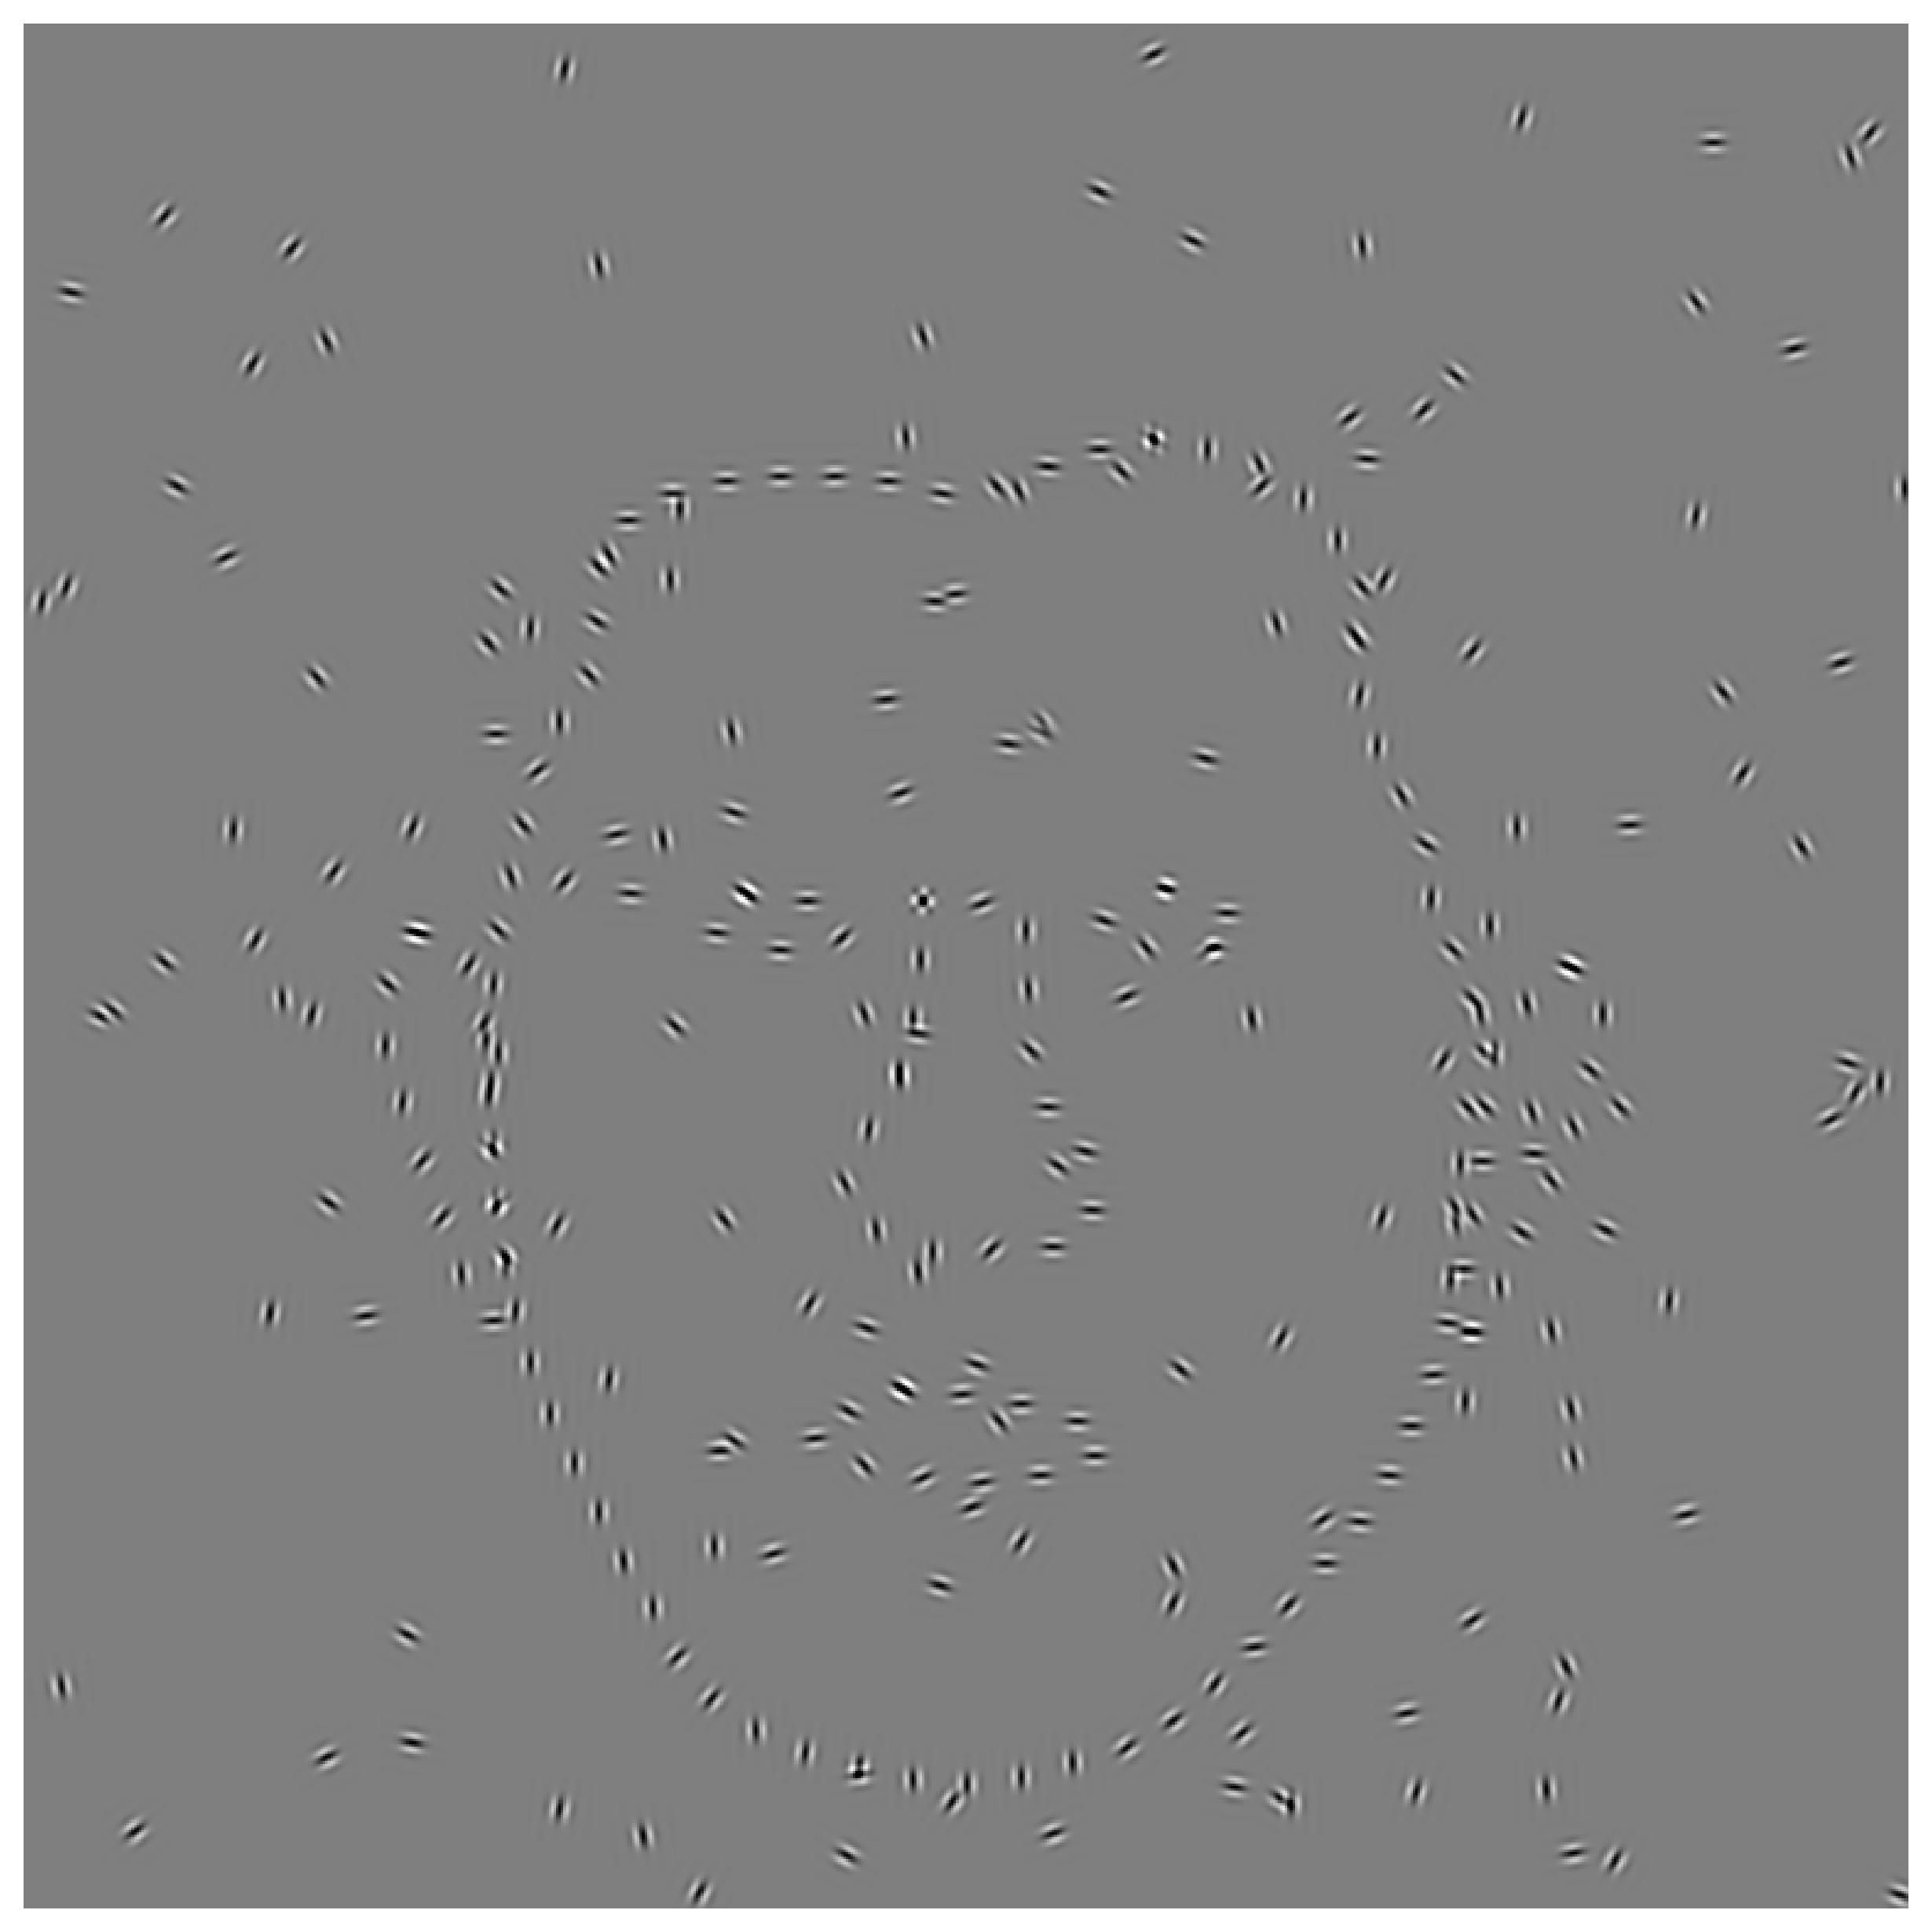

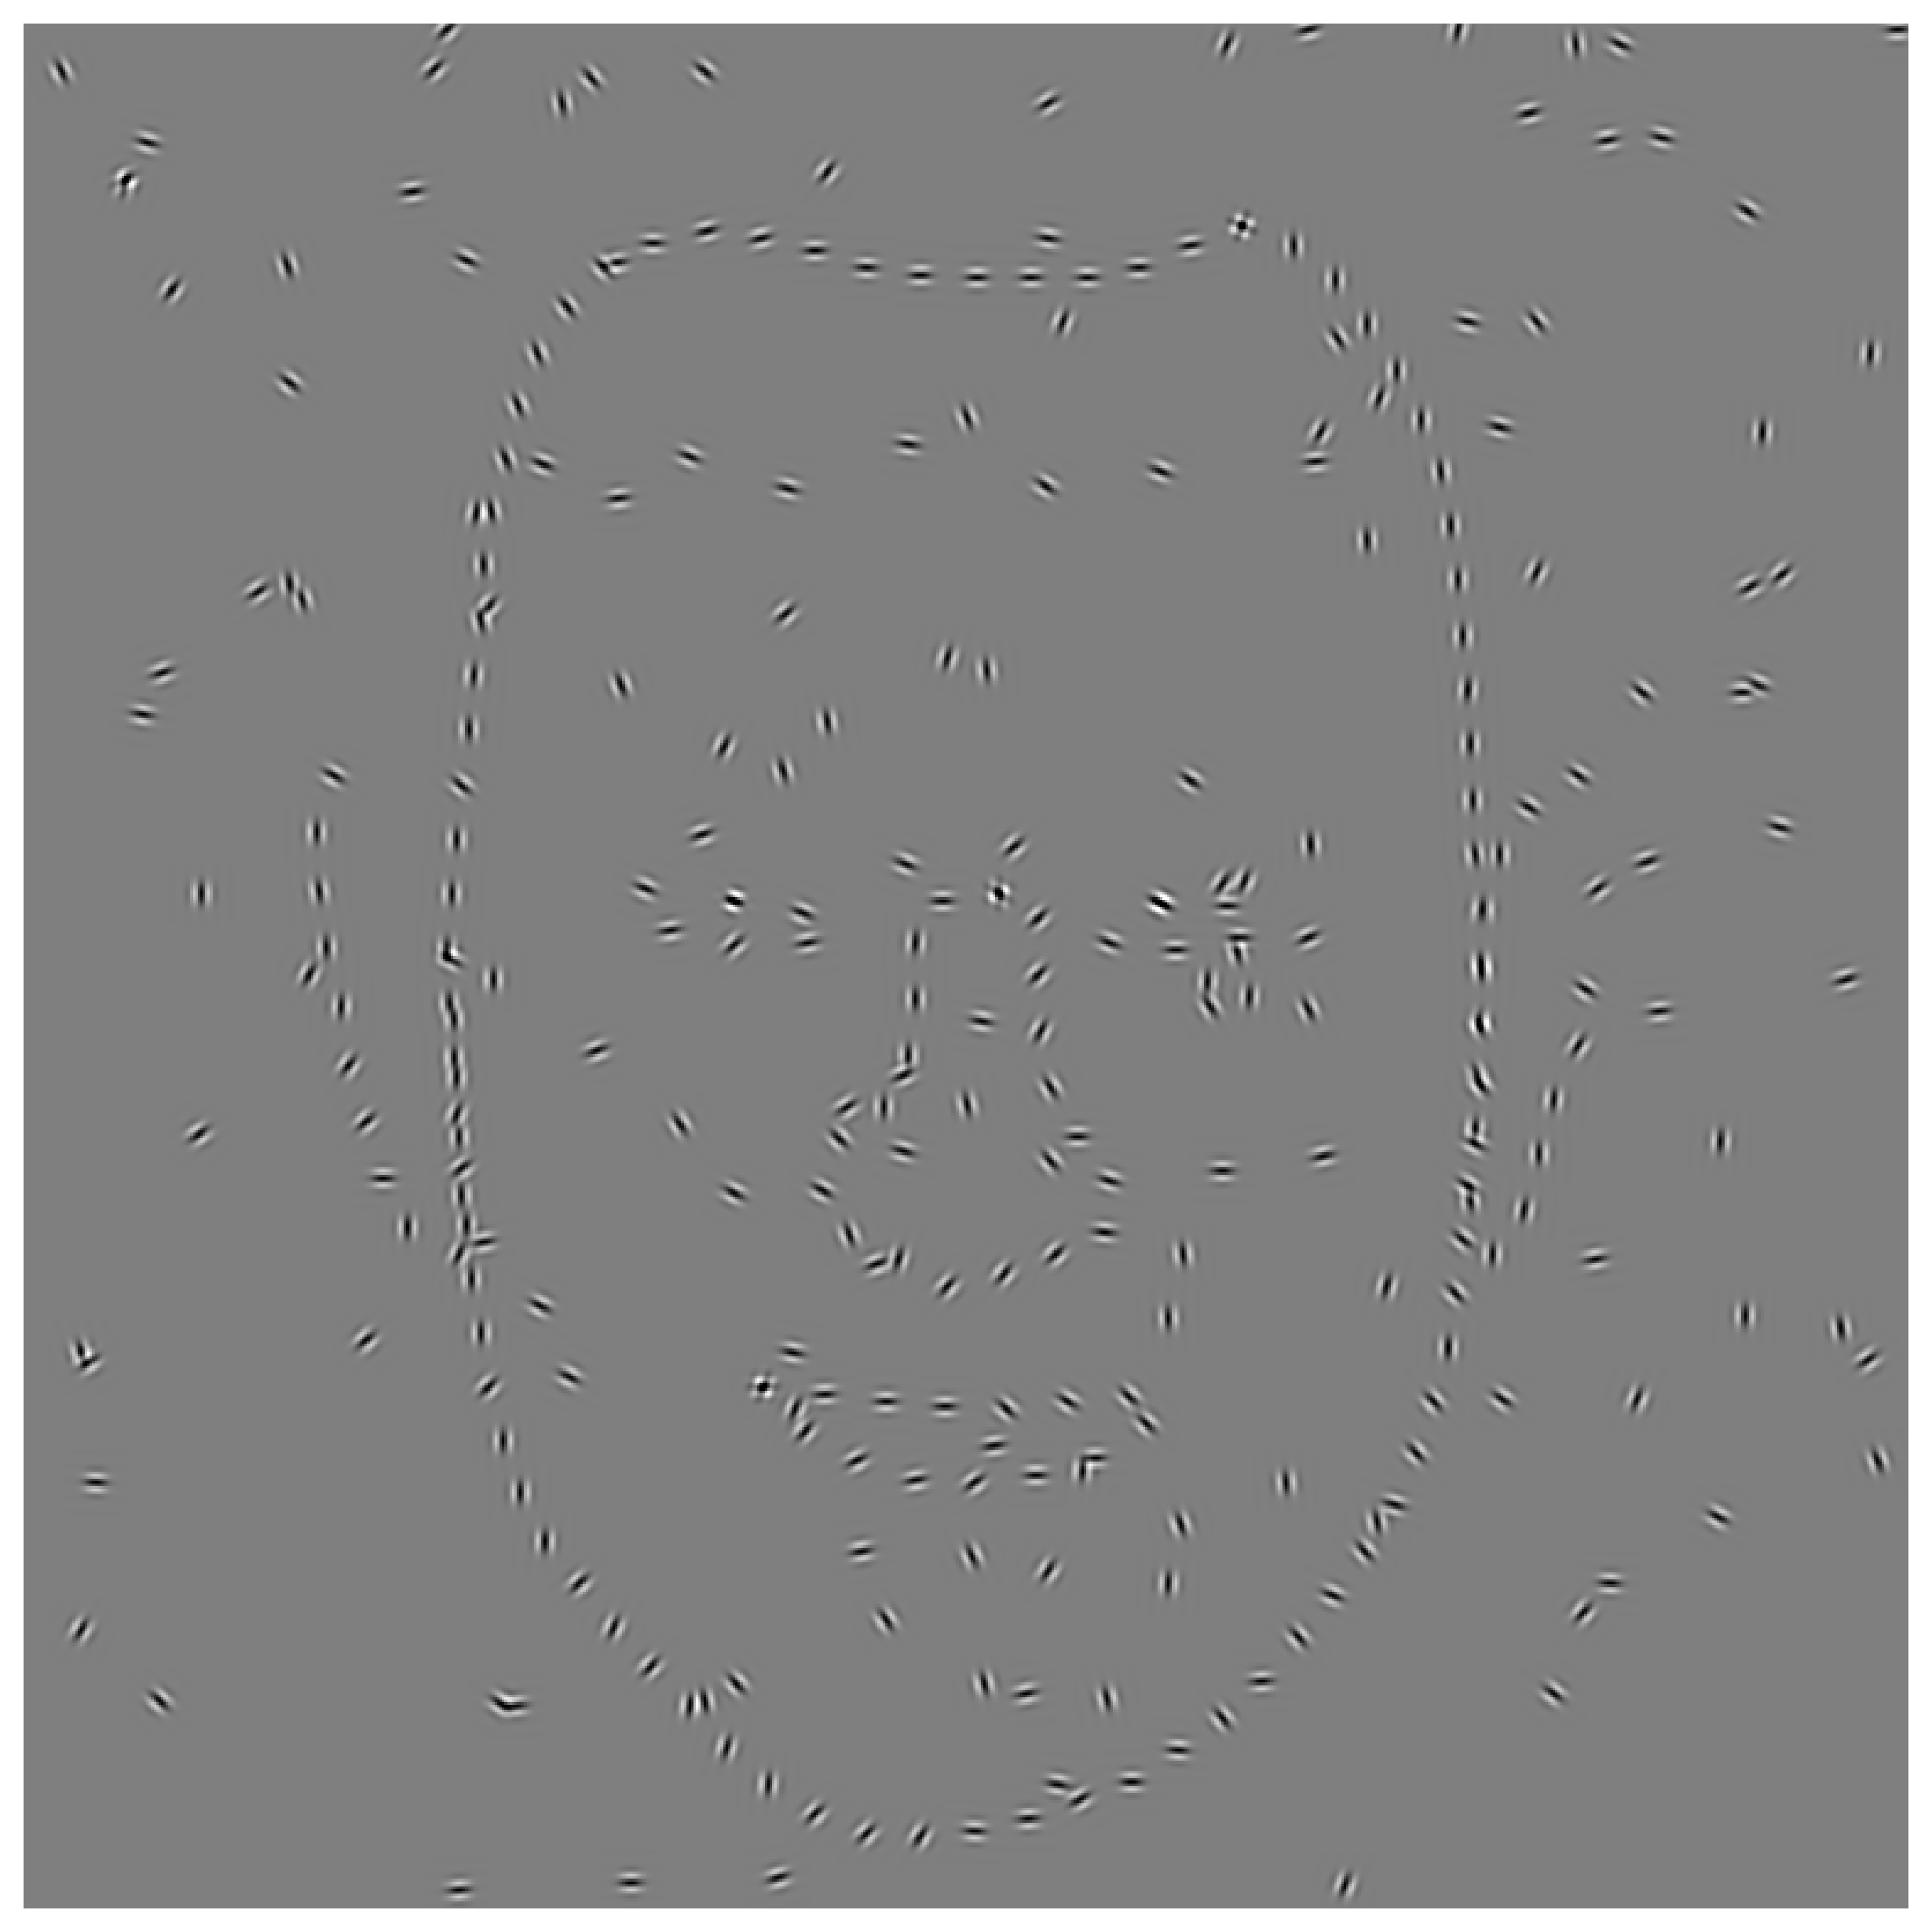

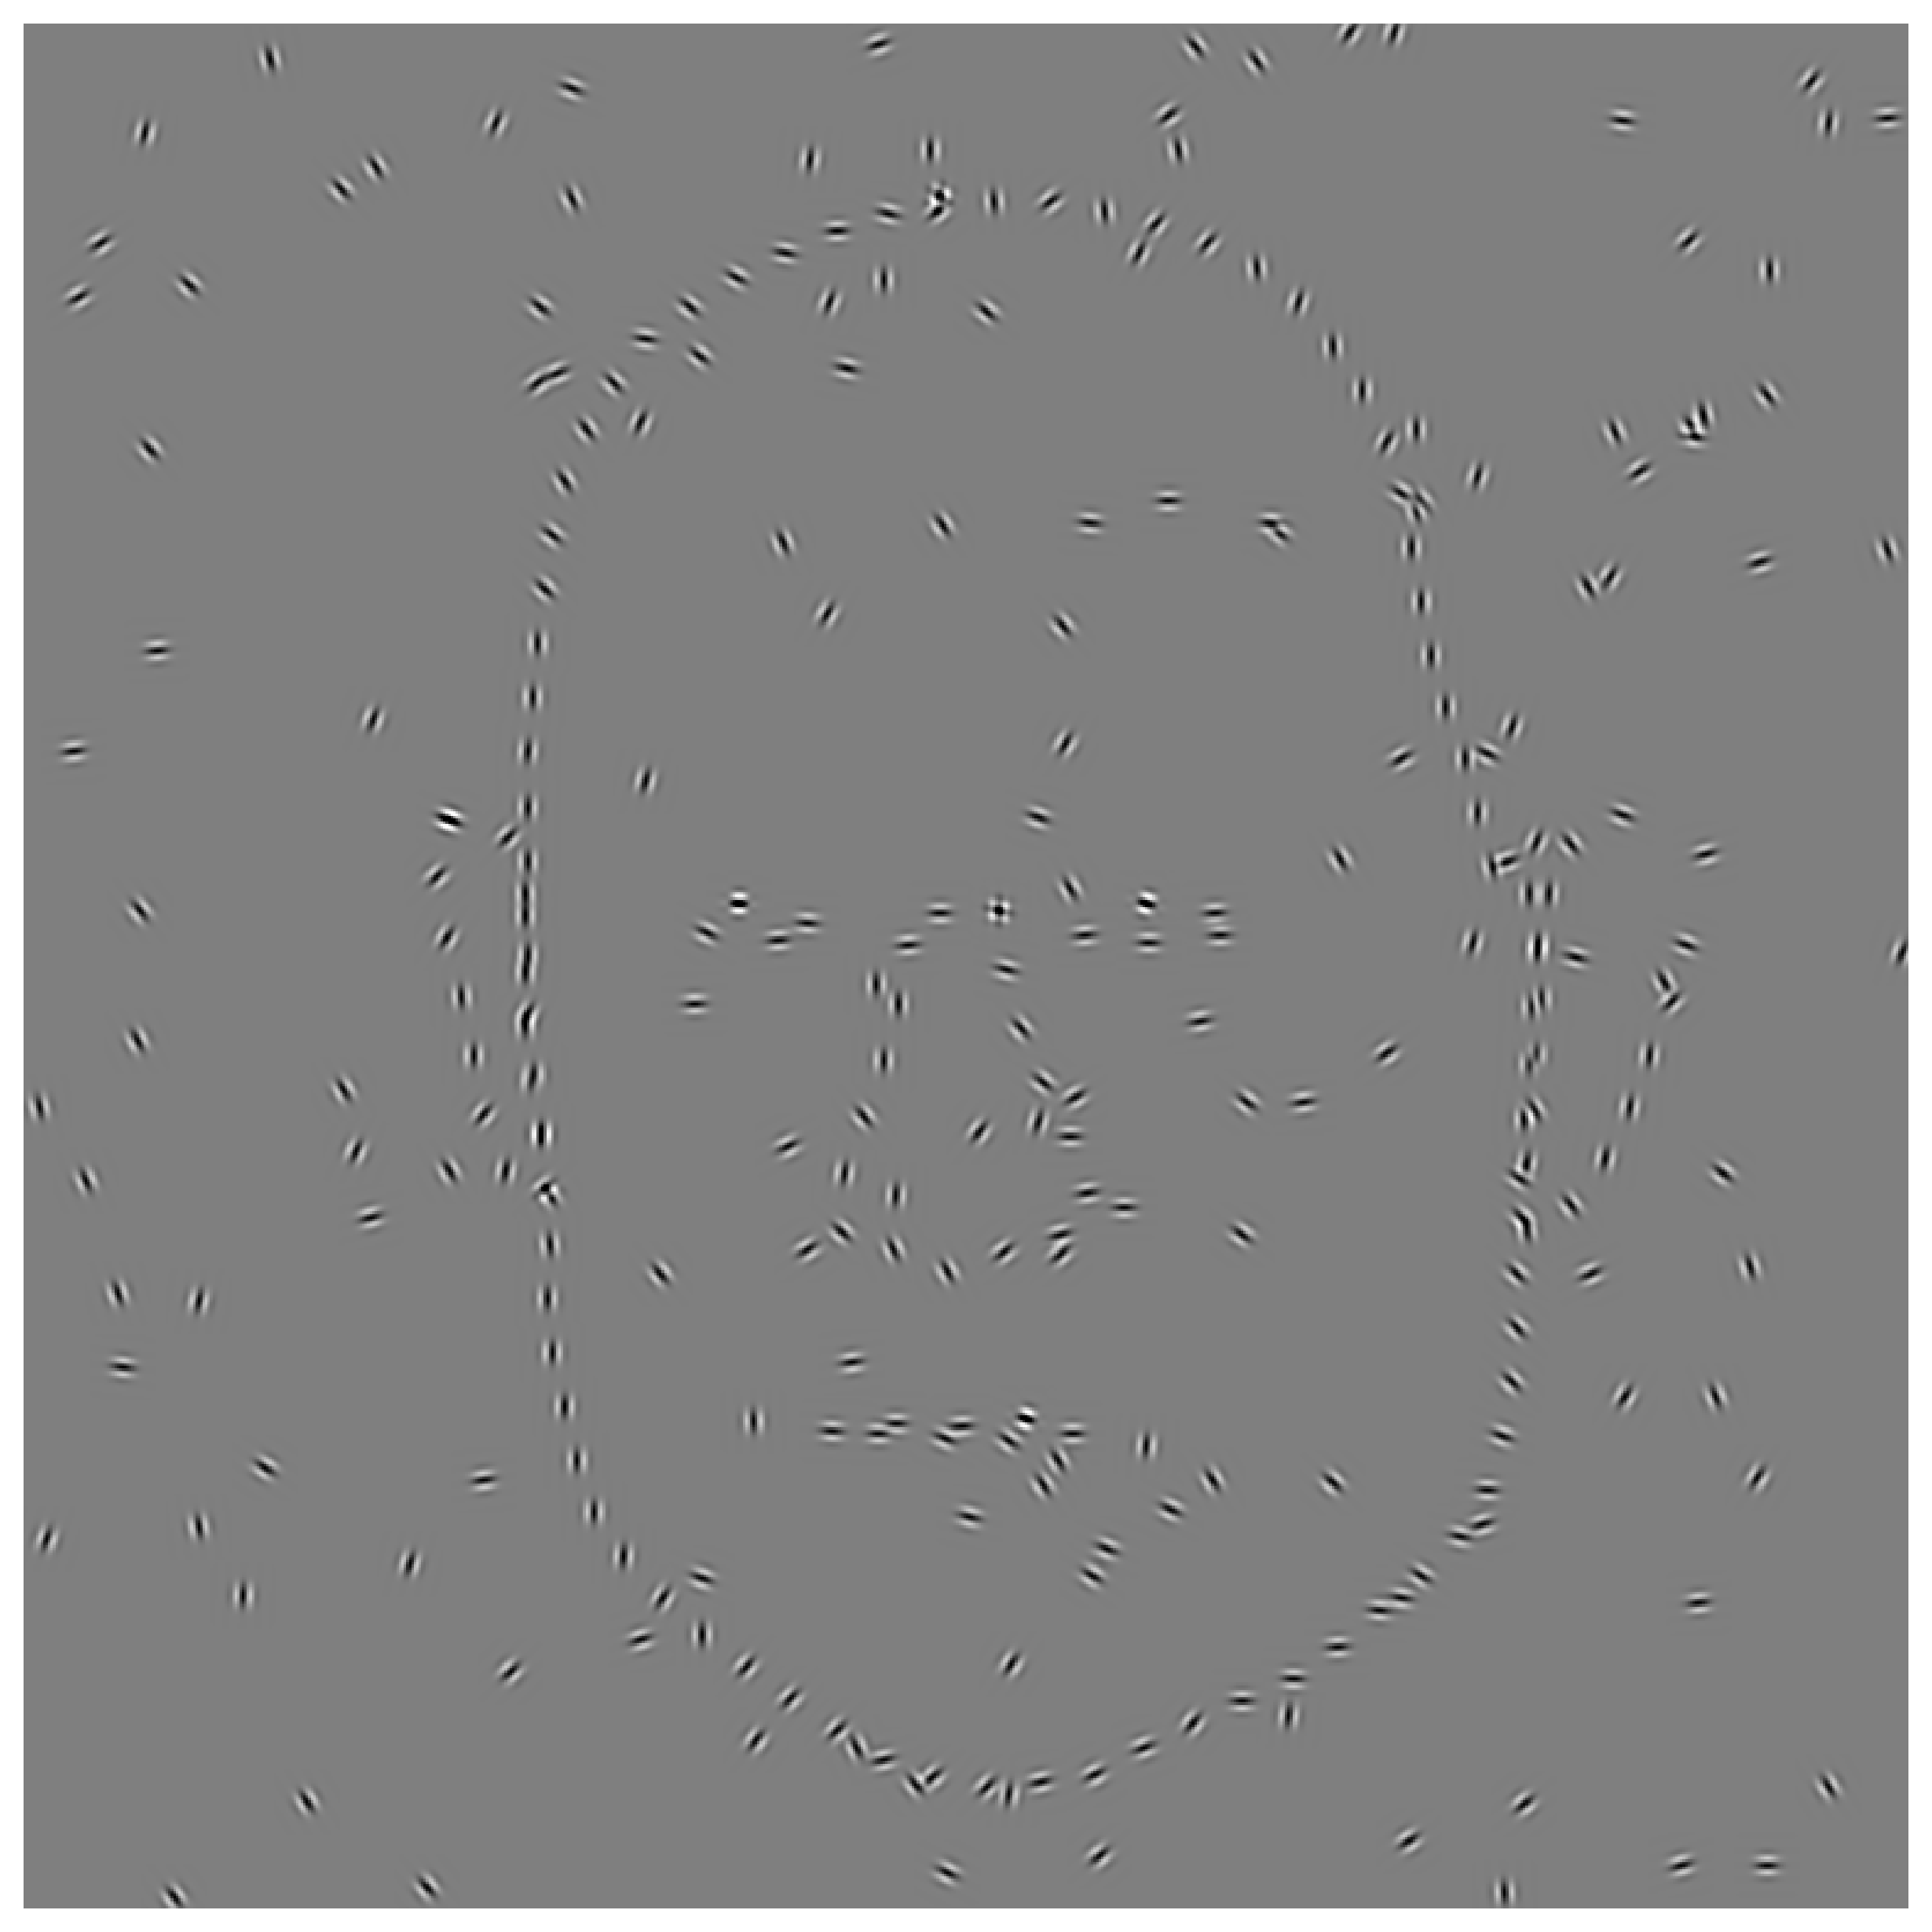

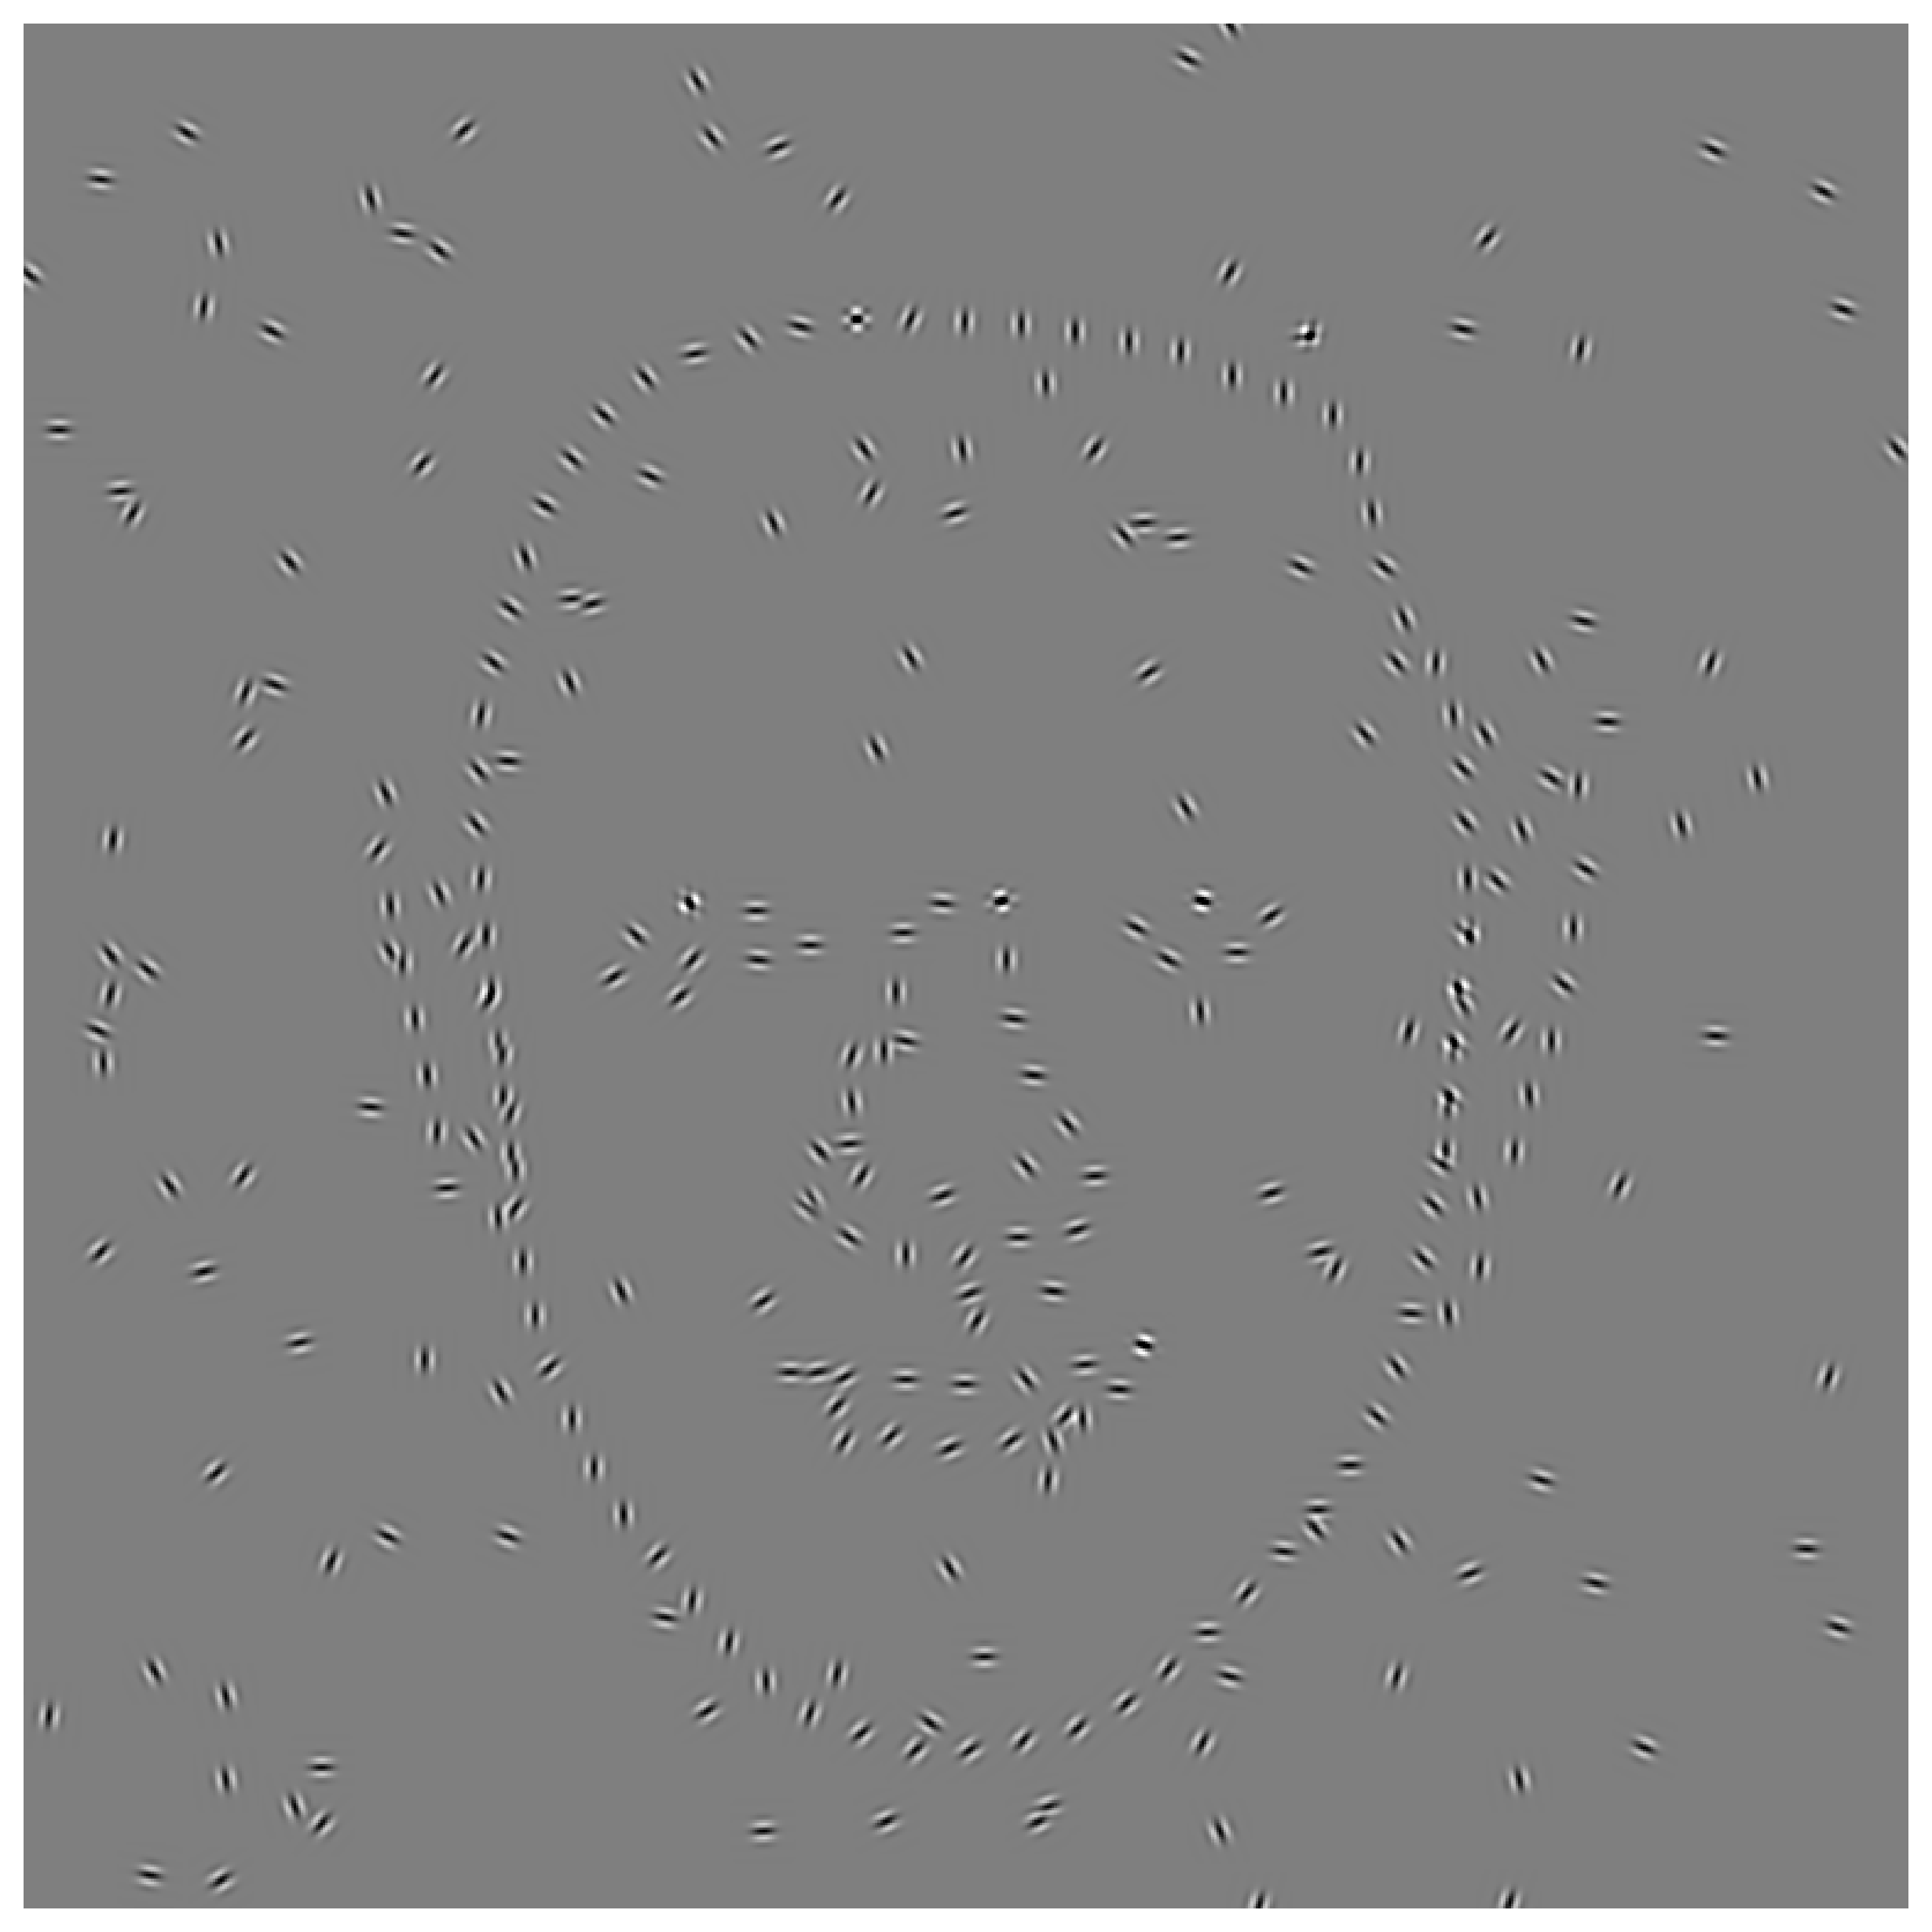

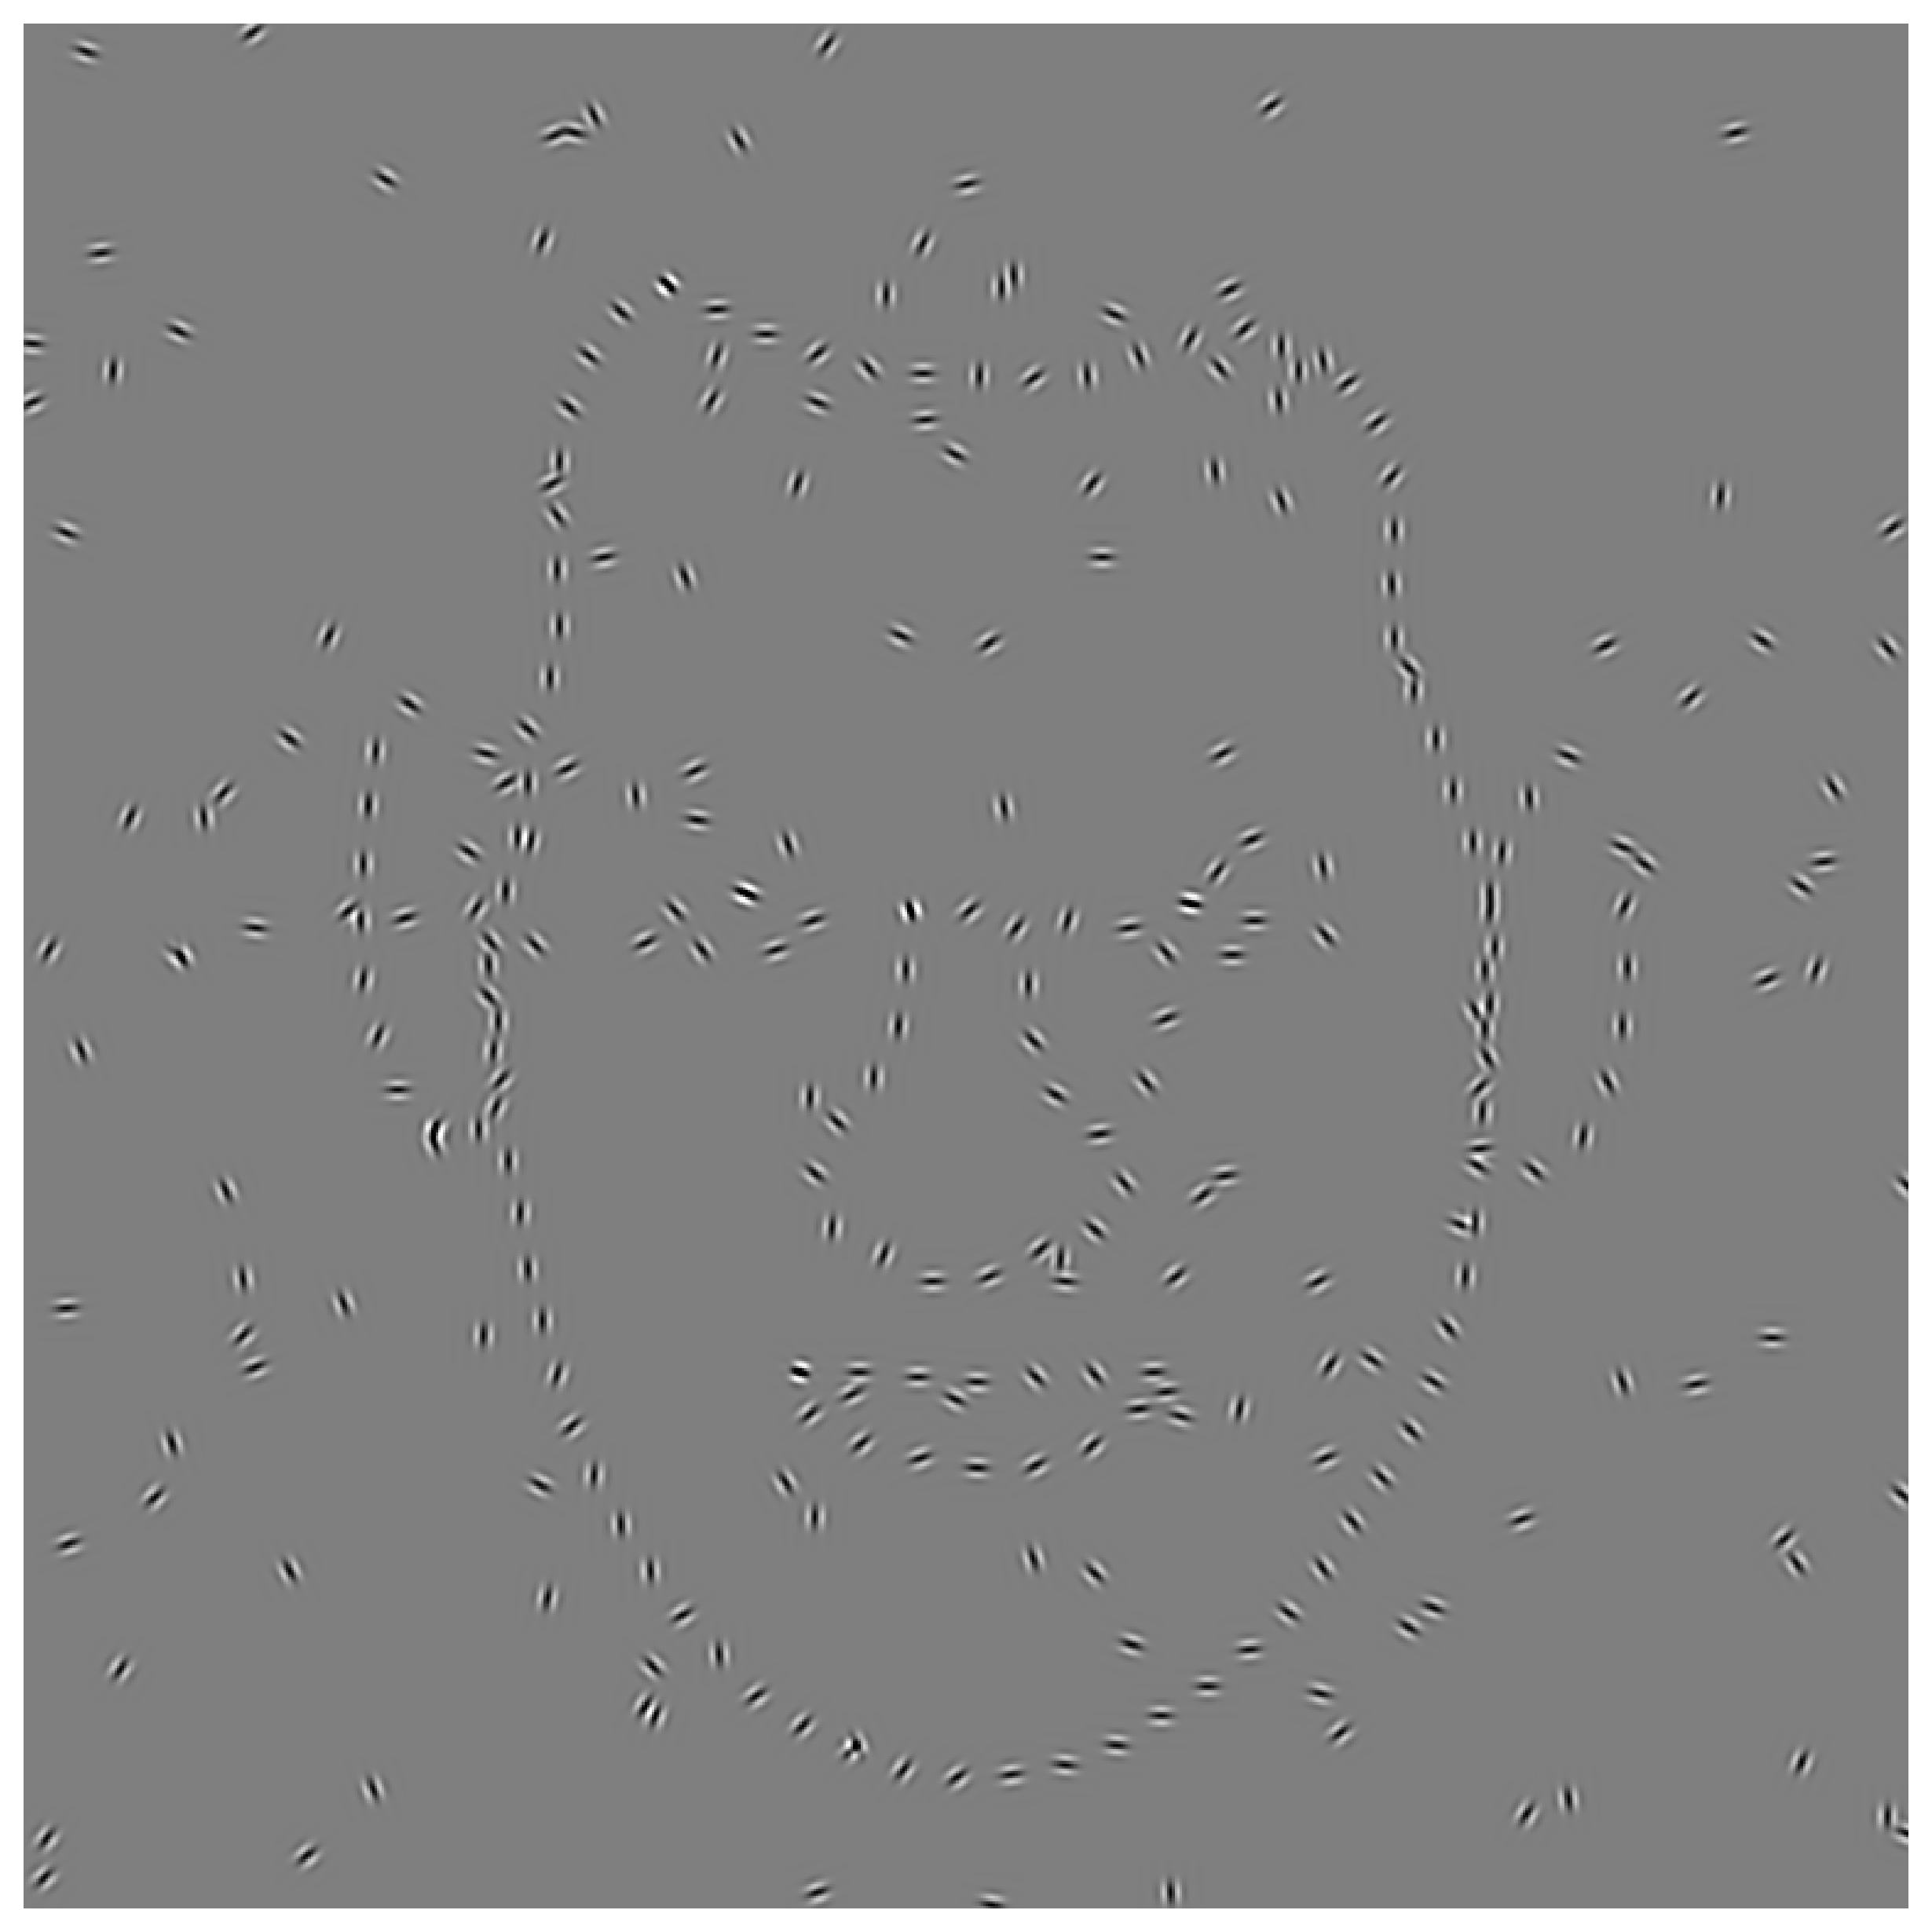

In [149]:
# ---- Parameters ----
face_annotation_types = {
    'r_ear': 15, 'r_eye': 10, 'skin': 90, 'nose': 25,
    'mouth': 20, 'l_eye': 10, 'l_ear': 15,
}
faces_annotation_num_points = list(face_annotation_types.values())
h, w = 768, 768  # Target image size for contours

# ---- Adaptive downsampling helper ----
def downsample_contour(points: np.ndarray, spacing: float = 12.0) -> np.ndarray:
    """Downsamples contour points so Gabors are evenly spaced."""
    if len(points) < 2:
        return points
    d = np.sqrt(np.sum(np.diff(points, axis=0)**2, axis=1))
    cumulative = np.concatenate(([0], np.cumsum(d)))
    total_len = cumulative[-1]
    n = max(2, int(total_len / spacing))
    new_t = np.linspace(0, total_len, n)
    new_x = np.interp(new_t, cumulative, points[:, 0])
    new_y = np.interp(new_t, cumulative, points[:, 1])
    return np.column_stack((new_x, new_y)).astype(np.float32)

for fidx, (fkey, fvalue) in enumerate(faces.items()):
    face = fvalue
    # ---- Contour extraction ----
    face_contours, face_angles = get_contour(
        face['mask_paths'],
        num_points=faces_annotation_num_points,
        smoothing_factor=1,
        target_shape=(h, w),
    )

    # ---- Adaptive resampling ----
    resampled_contours = [downsample_contour(pts, spacing=22) for pts in face_contours]
    resampled_angles = [ang[:len(pts)] + 90 for ang, pts in zip(face_angles, resampled_contours)]

    # ---- Stimulus generation ----
    stim_image = generate_gabor_stimuli(
        points_list=resampled_contours,
        angles_list=resampled_angles,
        image_size=(h, w),
        gabor_size=27,        # tighter, smaller Gabors
        spatial_freq=0.16,    # slightly higher frequency for clarity
        phase=np.pi,
        contrast=1.0,
        sigma=3.0,            # narrower Gaussian → sharper edges
        show=False,
        add_random=True,
        num_random=150,
        random_angle=True,
    )

    # ---- Save & Display ----
    os.makedirs('stim', exist_ok=True)
    out_path = os.path.join('stim', f"idx1_3_{fidx+1}_faces_{fkey}.png")
    plt.imsave(out_path, stim_image, cmap='gray', vmin=0, vmax=255)

    # ---- Display ----
    plt.figure(figsize=(8, 8), dpi=300)
    plt.imshow(stim_image, cmap='gray', origin='upper', vmin=0, vmax=255, interpolation='none')
    plt.axis('off')
    plt.tight_layout(pad=0)
    plt.show()
